# BÀI THỰC HÀNH 02: PHÂN CHIA TẬP TRAIN VÀ TEST
- Mục tiêu: Phân chia 80% Train (3.963 mẫu) và 20% Test (947 mẫu) chống rò rỉ dữ liệu.

In [1]:
from pathlib import Path
import sys,hashlib
import pandas as pd
import numpy as np
from IPython.display import display
assert sys.version_info[:2] == (3,14)
ROOT = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'dataLabanAI.xlsx').is_file())
workbook_path = ROOT/'dataLabanAI.xlsx'
sha_before = hashlib.sha256(workbook_path.read_bytes()).hexdigest()
sha_notebook00 = 'c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8'
assert sha_before == sha_notebook00, 'Workbook khác phiên bản Notebook 00; cần audit lại trước xử lý.'
excel = pd.ExcelFile(workbook_path)
assert excel.sheet_names == ['THONG_TIN','RIASEC_27','SO_THICH_6','CODEBOOK_33','KIEM_TRA']
raw_riasec = pd.read_excel(excel,sheet_name='RIASEC_27')
raw_q5 = pd.read_excel(excel,sheet_name='SO_THICH_6')
raw_codebook = pd.read_excel(excel,sheet_name='CODEBOOK_33')
# Bản sao gốc dùng đối chiếu, không thay đổi các DataFrame này.
original_riasec = raw_riasec.copy(deep=True)
original_q5 = raw_q5.copy(deep=True)
original_codebook = raw_codebook.copy(deep=True)
print('Python:',sys.version,'; Interpreter:',sys.executable)
print('SHA-256:',sha_before)
display(pd.DataFrame([{'Sheet':name,'Số dòng':len(frame),'Số cột':frame.shape[1]}
    for name,frame in [('RIASEC_27',raw_riasec),('SO_THICH_6',raw_q5),('CODEBOOK_33',raw_codebook)]]))


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)] ; Interpreter: C:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe
SHA-256: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8
         Sheet  Số dòng  Số cột
0    RIASEC_27     4910      28
1   SO_THICH_6     4910       7
2  CODEBOOK_33       33       5


In [2]:
question_columns = ['R1','I1','A1','R2','I2','A2','S1','S2','R3','A3','S3','E1','R4','S4','E2','R5','I3','A4','E3','I4','A5','E4','C1','E5','C2','C3','C4']
q5_columns = ['Q5_LikeRe','Q5_LikeIn','Q5_LikeAr','Q5_LikeSo','Q5_LikeEn','Q5_LikeCo']
survey_columns = question_columns+q5_columns
assert raw_riasec.shape == (4910,28) and raw_q5.shape == (4910,7)
assert list(raw_riasec.columns) == ['SOURCE_ROW']+question_columns
assert list(raw_q5.columns) == ['SOURCE_ROW']+q5_columns
assert raw_codebook.MA_COT.is_unique and raw_codebook.MA_COT.tolist() == survey_columns
assert raw_codebook.iloc[:27]['LOAI'].eq('RIASEC rút gọn').all()
assert raw_codebook.iloc[27:]['LOAI'].eq('Mức ưa thích nhóm nghề').all()
assert raw_codebook.iloc[:27]['THANG_DIEM_GOC'].nunique()==1
assert raw_codebook.iloc[27:]['THANG_DIEM_GOC'].nunique()==1
for frame in [raw_riasec,raw_q5]:
    assert frame.SOURCE_ROW.notna().all() and frame.SOURCE_ROW.is_unique
    assert pd.api.types.is_integer_dtype(frame.SOURCE_ROW)
assert set(raw_riasec.SOURCE_ROW) == set(raw_q5.SOURCE_ROW)
merged = raw_riasec.merge(raw_q5,on='SOURCE_ROW',how='outer',validate='one_to_one',indicator=True,sort=False)
display(merged['_merge'].value_counts().rename('Số dòng sau ghép').to_frame())
assert len(merged) == len(raw_riasec) == len(raw_q5) == 4910
assert merged['_merge'].eq('both').all()
merged = merged.drop(columns='_merge').set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW].reset_index()
assert merged.SOURCE_ROW.equals(raw_riasec.SOURCE_ROW)
assert merged[question_columns].equals(raw_riasec[question_columns])
assert merged[q5_columns].equals(raw_q5.set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW,q5_columns].reset_index(drop=True))
df_original = merged.copy(deep=True)
raw_survey = df_original[survey_columns].copy()
print('PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.')


PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.


            Số dòng sau ghép
_merge                      
both                    4910
left_only                  0
right_only                 0

In [3]:
type_rows = []
for col in survey_columns:
    values = raw_survey[col]
    numeric = pd.to_numeric(values,errors='coerce')
    is_numeric_cell = values.map(lambda value:isinstance(value,(int,float,np.integer,np.floating)) and not isinstance(value,(bool,np.bool_)))
    valid = is_numeric_cell & numeric.isin([1,2,3,4,5])
    type_rows.append({'Cột':col,'dtype gốc':str(values.dtype),'Thiếu':int(values.isna().sum()),
        'Sai kiểu hoặc ngoài miền':int((values.notna() & ~valid).sum()),
        'Min':numeric.min(),'Max':numeric.max(),'Số mức':numeric.nunique()})
type_check = pd.DataFrame(type_rows).set_index('Cột')
display(type_check)
if type_check['Thiếu'].sum() or type_check['Sai kiểu hoặc ngoài miền'].sum():
    raise RuntimeError('Có giá trị sai/thiếu; dừng để quyết định xử lý, không tự sửa.')
survey_int = raw_survey.astype('int64')
assert np.array_equal(survey_int.to_numpy(),raw_survey.to_numpy())
assert survey_int.isin(range(1,6)).all().all()
assert all(pd.api.types.is_integer_dtype(dtype) for dtype in survey_int.dtypes)
answers27 = survey_int[question_columns].copy()
preferences6 = survey_int[q5_columns].copy()
print('PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.')


PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.


          dtype gốc  Thiếu  Sai kiểu hoặc ngoài miền  Min  Max  Số mức
Cột                                                                   
R1            int64      0                         0    1    5       5
I1            int64      0                         0    1    5       5
A1            int64      0                         0    1    5       5
R2            int64      0                         0    1    5       5
I2            int64      0                         0    1    5       5
A2            int64      0                         0    1    5       5
S1            int64      0                         0    1    5       5
S2            int64      0                         0    1    5       5
R3            int64      0                         0    1    5       5
A3            int64      0                         0    1    5       5
S3            int64      0                         0    1    5       5
E1            int64      0                         0    1    5       5
R4    

## Bước 1: Phân chia bằng GroupShuffleSplit
- Chống rò rỉ dữ liệu: Nhóm theo vector 27 câu trả lời để vector trùng lặp không xuất hiện ở cả Train và Test.
- Đầu ra: Train 3.963 mẫu (80,71%), Test 947 mẫu (19,29%).

In [4]:
import sklearn
from sklearn.model_selection import GroupShuffleSplit
X = answers27.copy()
y = preferences6.copy()
SOURCE_ROW = df_original['SOURCE_ROW'].copy()
groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X),sort=False)[0],index=X.index,name='group_X27')
assert len(X)==4910 and X.shape[1]==27 and y.shape==(4910,6)
assert X.index.equals(y.index) and X.index.equals(groups.index)
assert X.index.is_unique and SOURCE_ROW.is_unique
assert groups.nunique()==4460
sizes = groups.value_counts()
assert sizes.gt(1).sum()==57 and sizes.loc[sizes.gt(1)].sum()==507
assert sizes.max()==188
assert X.nunique(axis=1).eq(1).sum()==347
assert X.var(axis=1,ddof=0).le(.1).sum()==597
splitter = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
train_pos,test_pos = next(splitter.split(X,groups=groups))
X_train,X_test = X.iloc[train_pos].copy(),X.iloc[test_pos].copy()
y_train,y_test = y.iloc[train_pos].copy(),y.iloc[test_pos].copy()
groups_train,groups_test = groups.iloc[train_pos].copy(),groups.iloc[test_pos].copy()
SOURCE_ROW_train,SOURCE_ROW_test = SOURCE_ROW.iloc[train_pos].copy(),SOURCE_ROW.iloc[test_pos].copy()
summary = pd.DataFrame({
    'Số dòng':[len(X_train),len(X_test),len(X)],
    'Tỷ lệ dòng (%)':[len(X_train)/len(X)*100,len(X_test)/len(X)*100,100],
    'Số group':[groups_train.nunique(),groups_test.nunique(),groups.nunique()],
    'Tỷ lệ group (%)':[groups_train.nunique()/groups.nunique()*100,groups_test.nunique()/groups.nunique()*100,100]},
    index=['Train','Test','Tổng'])
display(summary.round(4))
print('Shapes X_train/X_test/y_train/y_test:',X_train.shape,X_test.shape,y_train.shape,y_test.shape)
print('pandas/numpy/sklearn:',pd.__version__,np.__version__,sklearn.__version__)
# Chữ ký index theo int64 little-endian giúp đối chiếu chính xác ở notebook sau.
train_index_sha256 = hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()
test_index_sha256 = hashlib.sha256(np.asarray(X_test.index,dtype='<i8').tobytes()).hexdigest()
print('SHA-256 index Train:',train_index_sha256)
print('SHA-256 index Test: ',test_index_sha256)


Shapes X_train/X_test/y_train/y_test: (3963, 27) (947, 27) (3963, 6) (947, 6)
pandas/numpy/sklearn: 3.0.6 2.5.3 1.9.1
SHA-256 index Train: 471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d
SHA-256 index Test:  92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b


       Số dòng  Tỷ lệ dòng (%)  Số group  Tỷ lệ group (%)
Train     3963         80.7128      3568             80.0
Test       947         19.2872       892             20.0
Tổng      4910        100.0000      4460            100.0

## Bước 2: Kiểm tra phân bố nhãn mục tiêu Q5
- Xác nhận: Phân bố tần suất 5 mức sở thích trên hai tập có tính đồng nhất cao.

In [5]:
distribution_rows = []
for col in q5_columns:
    train_counts = y_train[col].value_counts().reindex(range(1,6),fill_value=0)
    test_counts = y_test[col].value_counts().reindex(range(1,6),fill_value=0)
    for level in range(1,6):
        distribution_rows.append({'Q5':col,'Mức':level,'Train n':int(train_counts[level]),
            'Test n':int(test_counts[level]),'Train (%)':train_counts[level]/len(y_train)*100,
            'Test (%)':test_counts[level]/len(y_test)*100})
distribution = pd.DataFrame(distribution_rows)
distribution['Test - Train (điểm %)'] = distribution['Test (%)']-distribution['Train (%)']
display(distribution.round(4))
assert distribution.groupby('Q5')['Train n'].sum().eq(len(y_train)).all()
assert distribution.groupby('Q5')['Test n'].sum().eq(len(y_test)).all()
small_support_threshold = 20
support_warnings = distribution.loc[(distribution['Train n']<small_support_threshold) |
                                     (distribution['Test n']<small_support_threshold)]
missing_levels = distribution.loc[distribution['Train n'].eq(0) | distribution['Test n'].eq(0)]
if support_warnings.empty:
    print('Không có mức Q5 nào dưới 20 mẫu trong mỗi tập.')
else:
    print('Cảnh báo mức có hỗ trợ nhỏ hoặc thiếu; giữ nguyên phép chia:')
    display(support_warnings)
if not missing_levels.empty:
    print('Có mức Q5 vắng mặt; cần xem xét khả năng đánh giá ở công đoạn sau, không tự đổi seed:')
    display(missing_levels)
distribution_difference = pd.DataFrame({
    'Chênh lệch tuyệt đối lớn nhất (điểm %)':distribution.groupby('Q5')['Test - Train (điểm %)'].apply(lambda s:s.abs().max()),
    'Total variation ×100':distribution.groupby('Q5')['Test - Train (điểm %)'].apply(lambda s:s.abs().sum()/2)})
display(distribution_difference.round(4))
print('Total variation ×100 = một nửa tổng chênh lệch tuyệt đối tỷ lệ 5 mức; 0 là hai phân bố trùng nhau, 100 là không chồng lấn.')


Không có mức Q5 nào dưới 20 mẫu trong mỗi tập.
Total variation ×100 = một nửa tổng chênh lệch tuyệt đối tỷ lệ 5 mức; 0 là hai phân bố trùng nhau, 100 là không chồng lấn.


           Q5  Mức  Train n  Test n  Train (%)  Test (%)  Test - Train (điểm %)
0   Q5_LikeRe    1     1092     270    27.5549   28.5111                 0.9562
1   Q5_LikeRe    2      963     224    24.2998   23.6536                -0.6461
2   Q5_LikeRe    3     1103     281    27.8325   29.6727                 1.8402
3   Q5_LikeRe    4      427     101    10.7747   10.6653                -0.1094
4   Q5_LikeRe    5      378      71     9.5382    7.4974                -2.0409
5   Q5_LikeIn    1      873     204    22.0288   21.5417                -0.4871
6   Q5_LikeIn    2      847     213    21.3727   22.4921                 1.1194
7   Q5_LikeIn    3     1079     249    27.2268   26.2936                -0.9333
8   Q5_LikeIn    4      637     168    16.0737   17.7402                 1.6666
9   Q5_LikeIn    5      527     113    13.2980   11.9324                -1.3656
10  Q5_LikeAr    1      747     186    18.8494   19.6410                 0.7916
11  Q5_LikeAr    2      734     186    1

           Chênh lệch tuyệt đối lớn nhất (điểm %)  Total variation ×100
Q5                                                                     
Q5_LikeAr                                  2.8631                3.4133
Q5_LikeCo                                  2.6855                5.1703
Q5_LikeEn                                  2.8631                4.9147
Q5_LikeIn                                  1.6666                2.7859
Q5_LikeRe                                  2.0409                2.7964
Q5_LikeSo                                  2.6296                2.6296

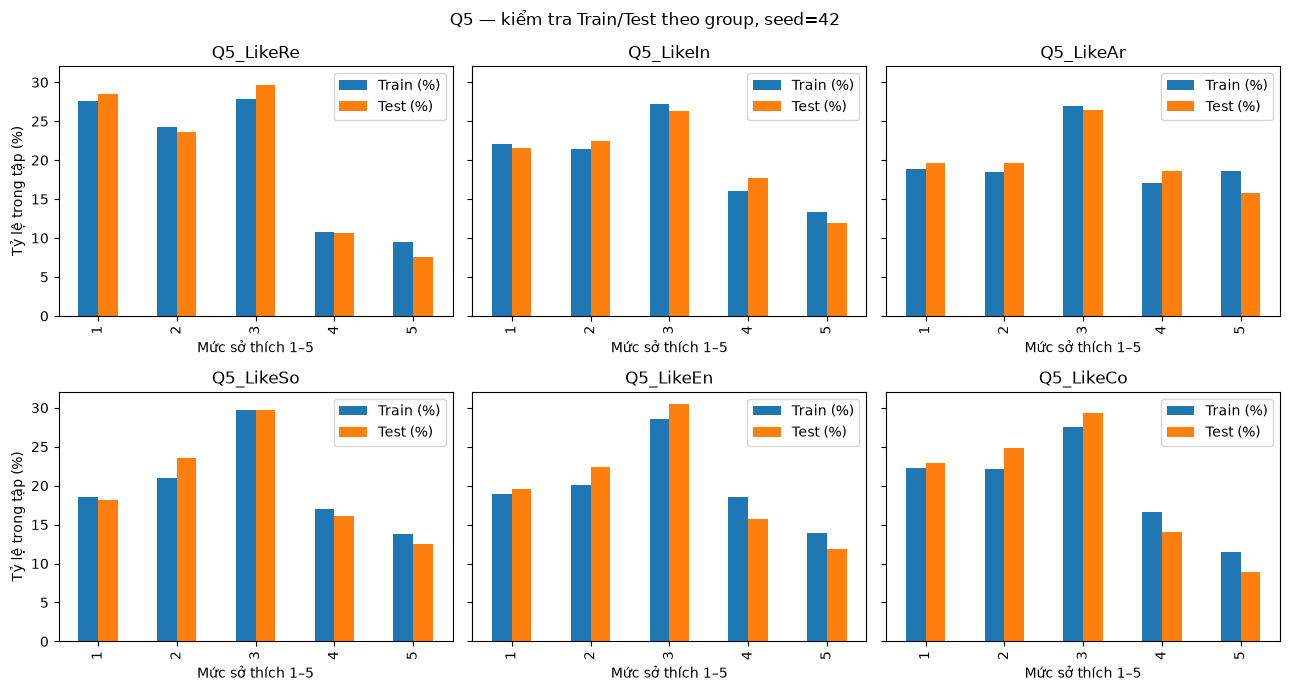

In [6]:
import matplotlib.pyplot as plt
fig,axes = plt.subplots(2,3,figsize=(13,7),sharey=True)
for ax,col in zip(axes.flat,q5_columns):
    data = distribution.loc[distribution['Q5'].eq(col)].set_index('Mức')[['Train (%)','Test (%)']]
    data.plot.bar(ax=ax)
    ax.set(title=col,xlabel='Mức sở thích 1–5',ylabel='Tỷ lệ trong tập (%)')
fig.suptitle('Q5 — kiểm tra Train/Test theo group, seed=42')
plt.tight_layout()
plt.show()

## Bước 3: Kiểm tra giao tập và chống rò rỉ dữ liệu
- Xác nhận: Giao tập giữa các nhóm Train và Test bằng rỗng; tổng số mẫu = 4.910.

In [7]:
assert len(X_train)+len(X_test)==4910
assert X_train.index.is_unique and X_test.index.is_unique
assert X_train.index.intersection(X_test.index).empty
assert set(X_train.index)|set(X_test.index)==set(X.index)
assert set(SOURCE_ROW_train).isdisjoint(SOURCE_ROW_test)
assert set(groups_train).isdisjoint(groups_test)
assert groups_train.nunique()+groups_test.nunique()==groups.nunique()
assert set(X_train.itertuples(index=False,name=None)).isdisjoint(X_test.itertuples(index=False,name=None))
assert list(X_train.columns)==list(X_test.columns)==question_columns
assert X_train.shape[1]==X_test.shape[1]==27
assert not set(q5_columns+['SOURCE_ROW']).intersection(X.columns)
assert list(y_train.columns)==list(y_test.columns)==q5_columns
assert y_train.shape[1]==y_test.shape[1]==6
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.equals(X.loc[X_train.index]) and X_test.equals(X.loc[X_test.index])
assert y_train.equals(y.loc[y_train.index]) and y_test.equals(y.loc[y_test.index])
assert np.array_equal(X.to_numpy(),df_original[question_columns].to_numpy())
assert np.array_equal(y.to_numpy(),df_original[q5_columns].to_numpy())
assert X.isin(range(1,6)).all().all() and y.isin(range(1,6)).all().all()
assignment = pd.Series('Train',index=X.index)
assignment.iloc[test_pos] = 'Test'
assert assignment.groupby(groups).nunique().eq(1).all()
largest_ids = sizes.index[sizes.eq(sizes.max())]
largest_report = pd.DataFrame({'Số dòng':sizes.loc[largest_ids]})
largest_report['Tập'] = ['Train' if group in set(groups_train) else 'Test' for group in largest_ids]
# Không in mã group hoặc SOURCE_ROW.
print('Nhóm vector lặp lớn nhất:')
print(largest_report.to_string(index=False))
for group in largest_ids:
    positions = groups.index[groups.eq(group)]
    assert assignment.loc[positions].nunique()==1
    assert len(positions)==sizes.max()
sha_after = hashlib.sha256(workbook_path.read_bytes()).hexdigest()
assert sha_after==sha_before
pd.testing.assert_frame_equal(raw_riasec,original_riasec)
pd.testing.assert_frame_equal(raw_q5,original_q5)
pd.testing.assert_frame_equal(raw_codebook,original_codebook)
pd.testing.assert_frame_equal(df_original,merged)
print('PASS: tất cả kiểm tra leakage; mọi vector lặp nằm trọn một tập, dữ liệu đầu vào không đổi.')
print('SHA-256 workbook sau:',sha_after)


Nhóm vector lặp lớn nhất:
 Số dòng   Tập
     188 Train
PASS: tất cả kiểm tra leakage; mọi vector lặp nằm trọn một tập, dữ liệu đầu vào không đổi.
SHA-256 workbook sau: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8


## Bước 4: Đóng băng tập dữ liệu nghiên cứu và Tổng kết
- Quy tắc: Tập Test (947 mẫu) được đóng băng tuyệt đối, chỉ sử dụng ở Bài 07.